### Example 4: reflection experiment (Figure S2)

A dipole, formed by two point sources of strength $+1$ and $-1$ at $(0, 0.46)$ m and $(0, 0.54)$ m, radiates at $f = 1$ GHz into the domain $\Omega_\mathrm{i} = [-15, 15] \times [0, 5]$ m.

The domain is truncated by absorbing layers of the same type as the method under test: $n = 30$ cells ($L \approx 1\lambda$) for the Ren–Liu and PML methods, and $n=1$ for EM1, EM2, and H2.

Only the bottom boundary ($y = 0$) is under test. The reflection coefficient $R$ is extracted with the Tamura method from two sampling lines at $y_1 = 0.05$ m and $y_2 = 0.1$ m, spanning from $x$ = -12 m to 12 m with spacing $\Delta x = 0.01$ m (equal to grid size $h$). A Tukey window with $\alpha = 0.2$ was used for the FFT. In these simulutaion, the grid spacing is $h = 0.01$ m and the finite-difference order is 4.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pyhelmholtz as ph
from compute_reflection import compute_tamura_reflection, compute_abc_reflection

#### 1) Experimental setup

In [ ]:
##### domain definition
xpmin, xpmax = -15.0, 15.0
ypmin, ypmax = 0.0, 5.0
h = 0.01

##### source information
# source_type = "monopole_source"
source_type = "dipole_source"

freq = 1.0e+9

v0 = ph.LIGHT_SPEED
wlen0 = v0/freq
k0 = 2*np.pi/wlen0
k_bg = k0

if source_type == "monopole_source":
    xsrc0 = 0.0
    ysrc0 = 0.5 
    xsrc = np.array([xsrc0])
    ysrc = np.array([ysrc0])
    strength = np.array([1])

elif source_type == "dipole_source":
    xsrc0 = 0.0
    ysrc0, d_half = 0.5, 0.04

    ysrc1, ysrc2 = ysrc0 - d_half, ysrc0 + d_half
    xsrc = np.array([xsrc0, xsrc0])
    ysrc = np.array([ysrc1, ysrc2])
    strength = np.array([1, -1])

##### measurement plane
y0 = ypmin + 0.0 # interface between interior domain and absorbing domain

y1, y2 = 0.05, 0.10
xstart, xend = -12.0, 12.0
nslice = 1 # sampling rate
x_step = h*nslice

##### Absorbing boundary parameters
n = 30 # physical thickness = 1λ for grid size h = 0.01 m
R0 = 1e-4 # target normal-incidence reflection coefficients

##### Numerical setting
fd_order = 4
alpha_tukey = 0.2

#### 2) Calculate/Load the simulated solution for each ABMs

In [3]:
# convert physical coordinates (x, y) to grid indices
ixstart, ixend = round((xstart-xpmin)/h), round((xend-xpmin)/h)
iymm, iy1, iy2 = round((y0-ypmin)/h), round((y1-ypmin)/h), round((y2-ypmin)/h)

# boundary of interior domain
ext_interior = np.array([xpmin, xpmax, ypmin, ypmax])

In [ ]:
# create a function to compute the wavefield and the reflection coefficient using the Tamura method
# with given parameters in previous cell

def compute_wavefield_and_reflection_profile(abm_name):

    h_str = f"h{round(h/0.01)}cm" 
    
    try:
        usim_2d = np.load(f"wavefield_data/usim_{abm_name}_FD4_h1cm.npy")

    except FileNotFoundError:

        # initialize parameter
        limits = (xpmin, xpmax, ypmin, ypmax)
        domain = ph.Domain(limits=limits, h=h)
        source = ph.PointSource(freq, xs=xsrc, ys=ysrc, strength=strength)

        # define absorbing boundary method used
        if abm_name in ["EM1", "EM2", "H2"]:
            abm = ph.RenLiu(abm=abm_name)

        if abm_name in ["RLEM1", "RLEM2", "RLH2"]:
            abm = ph.RenLiu(abm=abm_name, n=n)   

        elif abm_name in ["PML0", "PMLEM1", "PMLEM2", "PMLH2"]:
            abm = ph.PML(abm=abm_name, n=n, R0=R0)       

        # create Helmholtz objects
        ho = ph.Helmholtz(domain=domain, source=source,
                          abm=abm, fd=ph.FD(fd_order))

        # solve for the wavefield
        ho.solve("mumps")

        # save file
        np.save(f"wavefield_data/usim_{abm_name}_FD4_{h_str}.npy", ho.u)
        usim_2d = ho.u

    # extract two horizontal line probes of the wavefield u, keeping every nslice-th point
    ut_line1 = usim_2d[iy1, ixstart:ixend+1][::nslice]
    ut_line2 = usim_2d[iy2, ixstart:ixend+1][::nslice]

    # compute the reflection coefficient using the Tamura method
    exp_setting = x_step, y0, y1, y2, k_bg
    alg_setting = ("non_padding", alpha_tukey)
    R, angle = compute_tamura_reflection(ut_line1, ut_line2, exp_setting, alg_setting)

    # visualization
    plt.figure(figsize=(15, 5))
    plt.imshow(np.flipud(np.real(usim_2d)), cmap="jet", vmin=-0.15, vmax=0.10, extent=ext_interior)
    plt.title(f"Real part of wavefield solved via {abm_name} method")
    plt.colorbar(shrink=0.5); plt.show()

    return R, angle

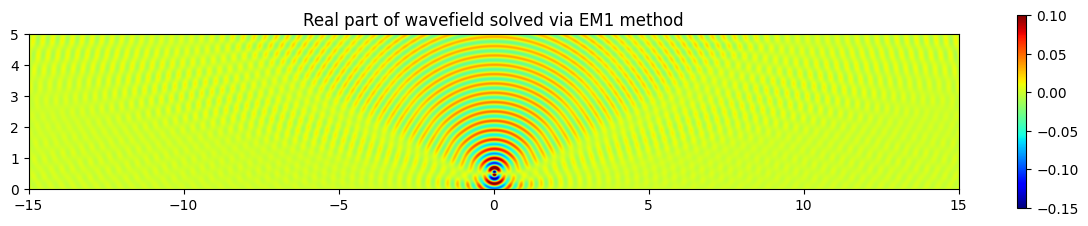

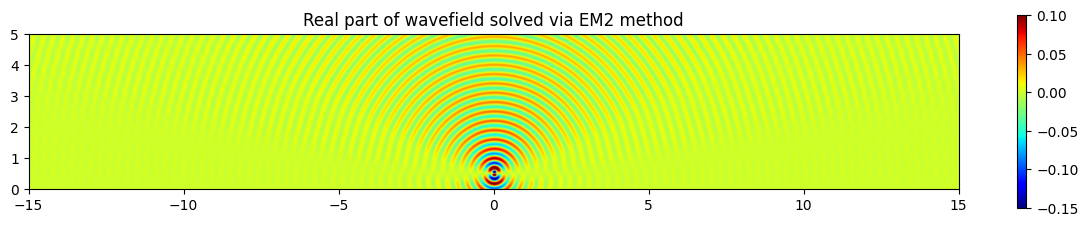

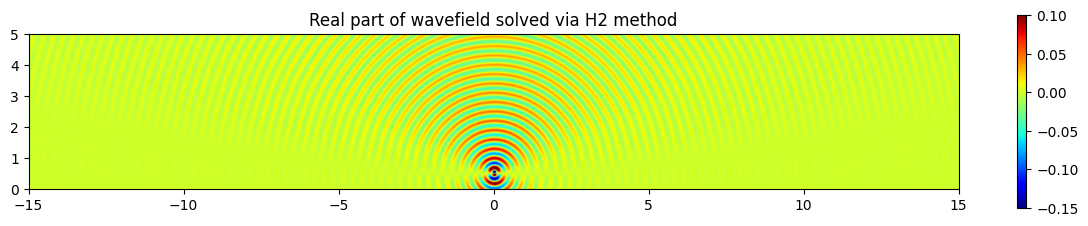

In [5]:
R_EM1, angle = compute_wavefield_and_reflection_profile("EM1") # execution time = 13 min (use MUMPS)
R_EM2, _ = compute_wavefield_and_reflection_profile("EM2") # execution time = 14 min (use MUMPS)
R_H2, _ = compute_wavefield_and_reflection_profile("H2") # execution time = 14 min (use MUMPS)

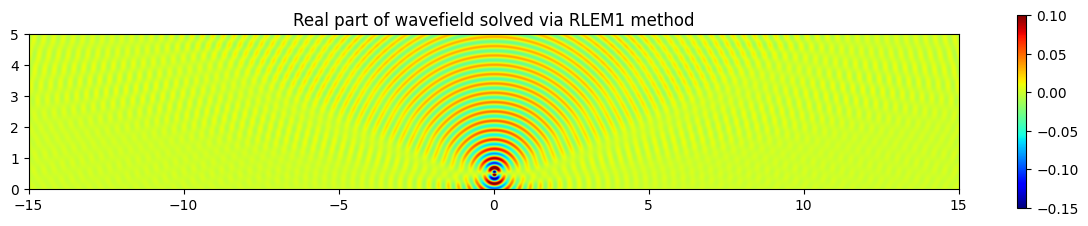

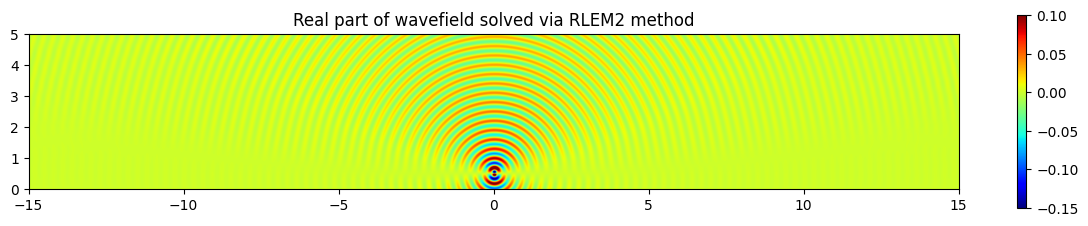

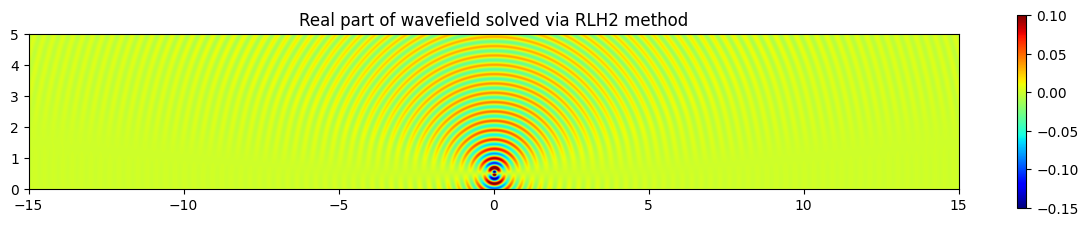

In [6]:
R_RLEM1, angle = compute_wavefield_and_reflection_profile("RLEM1") # execution time = 21 min (use MUMPS)
R_RLEM2, _ = compute_wavefield_and_reflection_profile("RLEM2") # execution time = 44 min (use MUMPS)
R_RLH2, _ = compute_wavefield_and_reflection_profile("RLH2")  # execution time = 19 min (use spsolve)

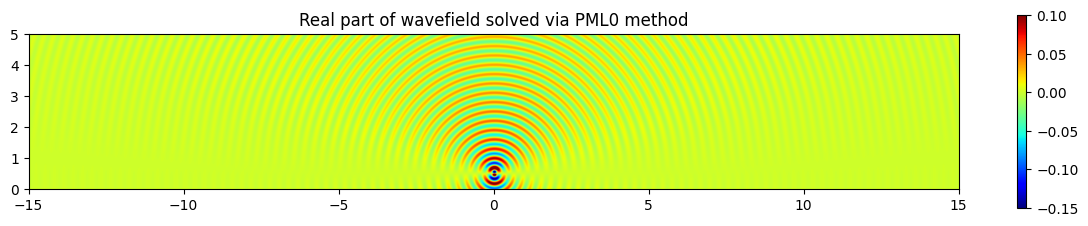

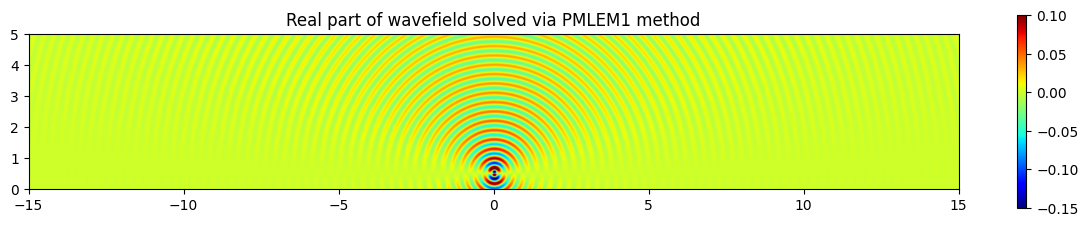

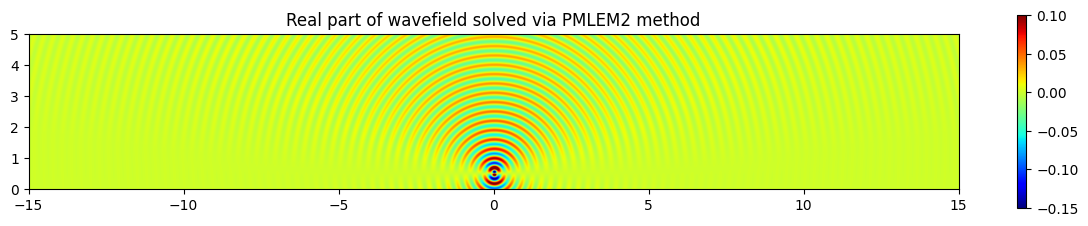

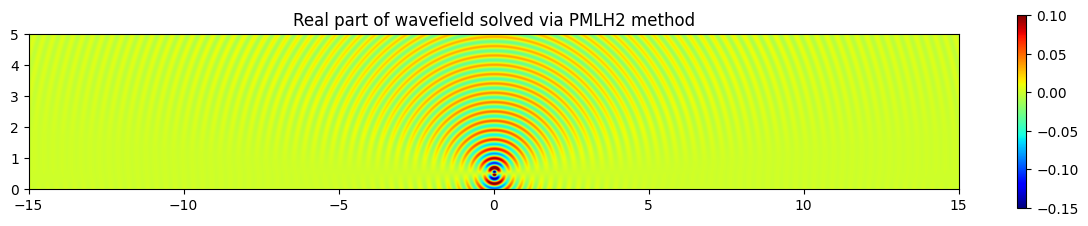

In [7]:
R_PML0, angle = compute_wavefield_and_reflection_profile("PML0") # execution time = 12 min (use spsolve)
R_PMLEM1, _ = compute_wavefield_and_reflection_profile("PMLEM1") # execution time = 17 min (use spsolve)
R_PMLEM2, _ = compute_wavefield_and_reflection_profile("PMLEM2") # execution time = 15 min (use spsolve)
R_PMLH2, _ = compute_wavefield_and_reflection_profile("PMLH2") # execution time = 18 min (use spsolve)

#### 3) Compute theoretical reflection coefficient

In [ ]:
# compute theoretical reflection coefficient
R_EM1_exact = compute_abc_reflection(angle, "EM1")
R_EM2_exact = compute_abc_reflection(angle, "EM2")
R_H2_exact = compute_abc_reflection(angle, "H2")
R_PML0_exact = compute_abc_reflection(angle, "PML0", R0=R0)

#### 4) Plot the results compared to the theoretical curves (Fig. S2)

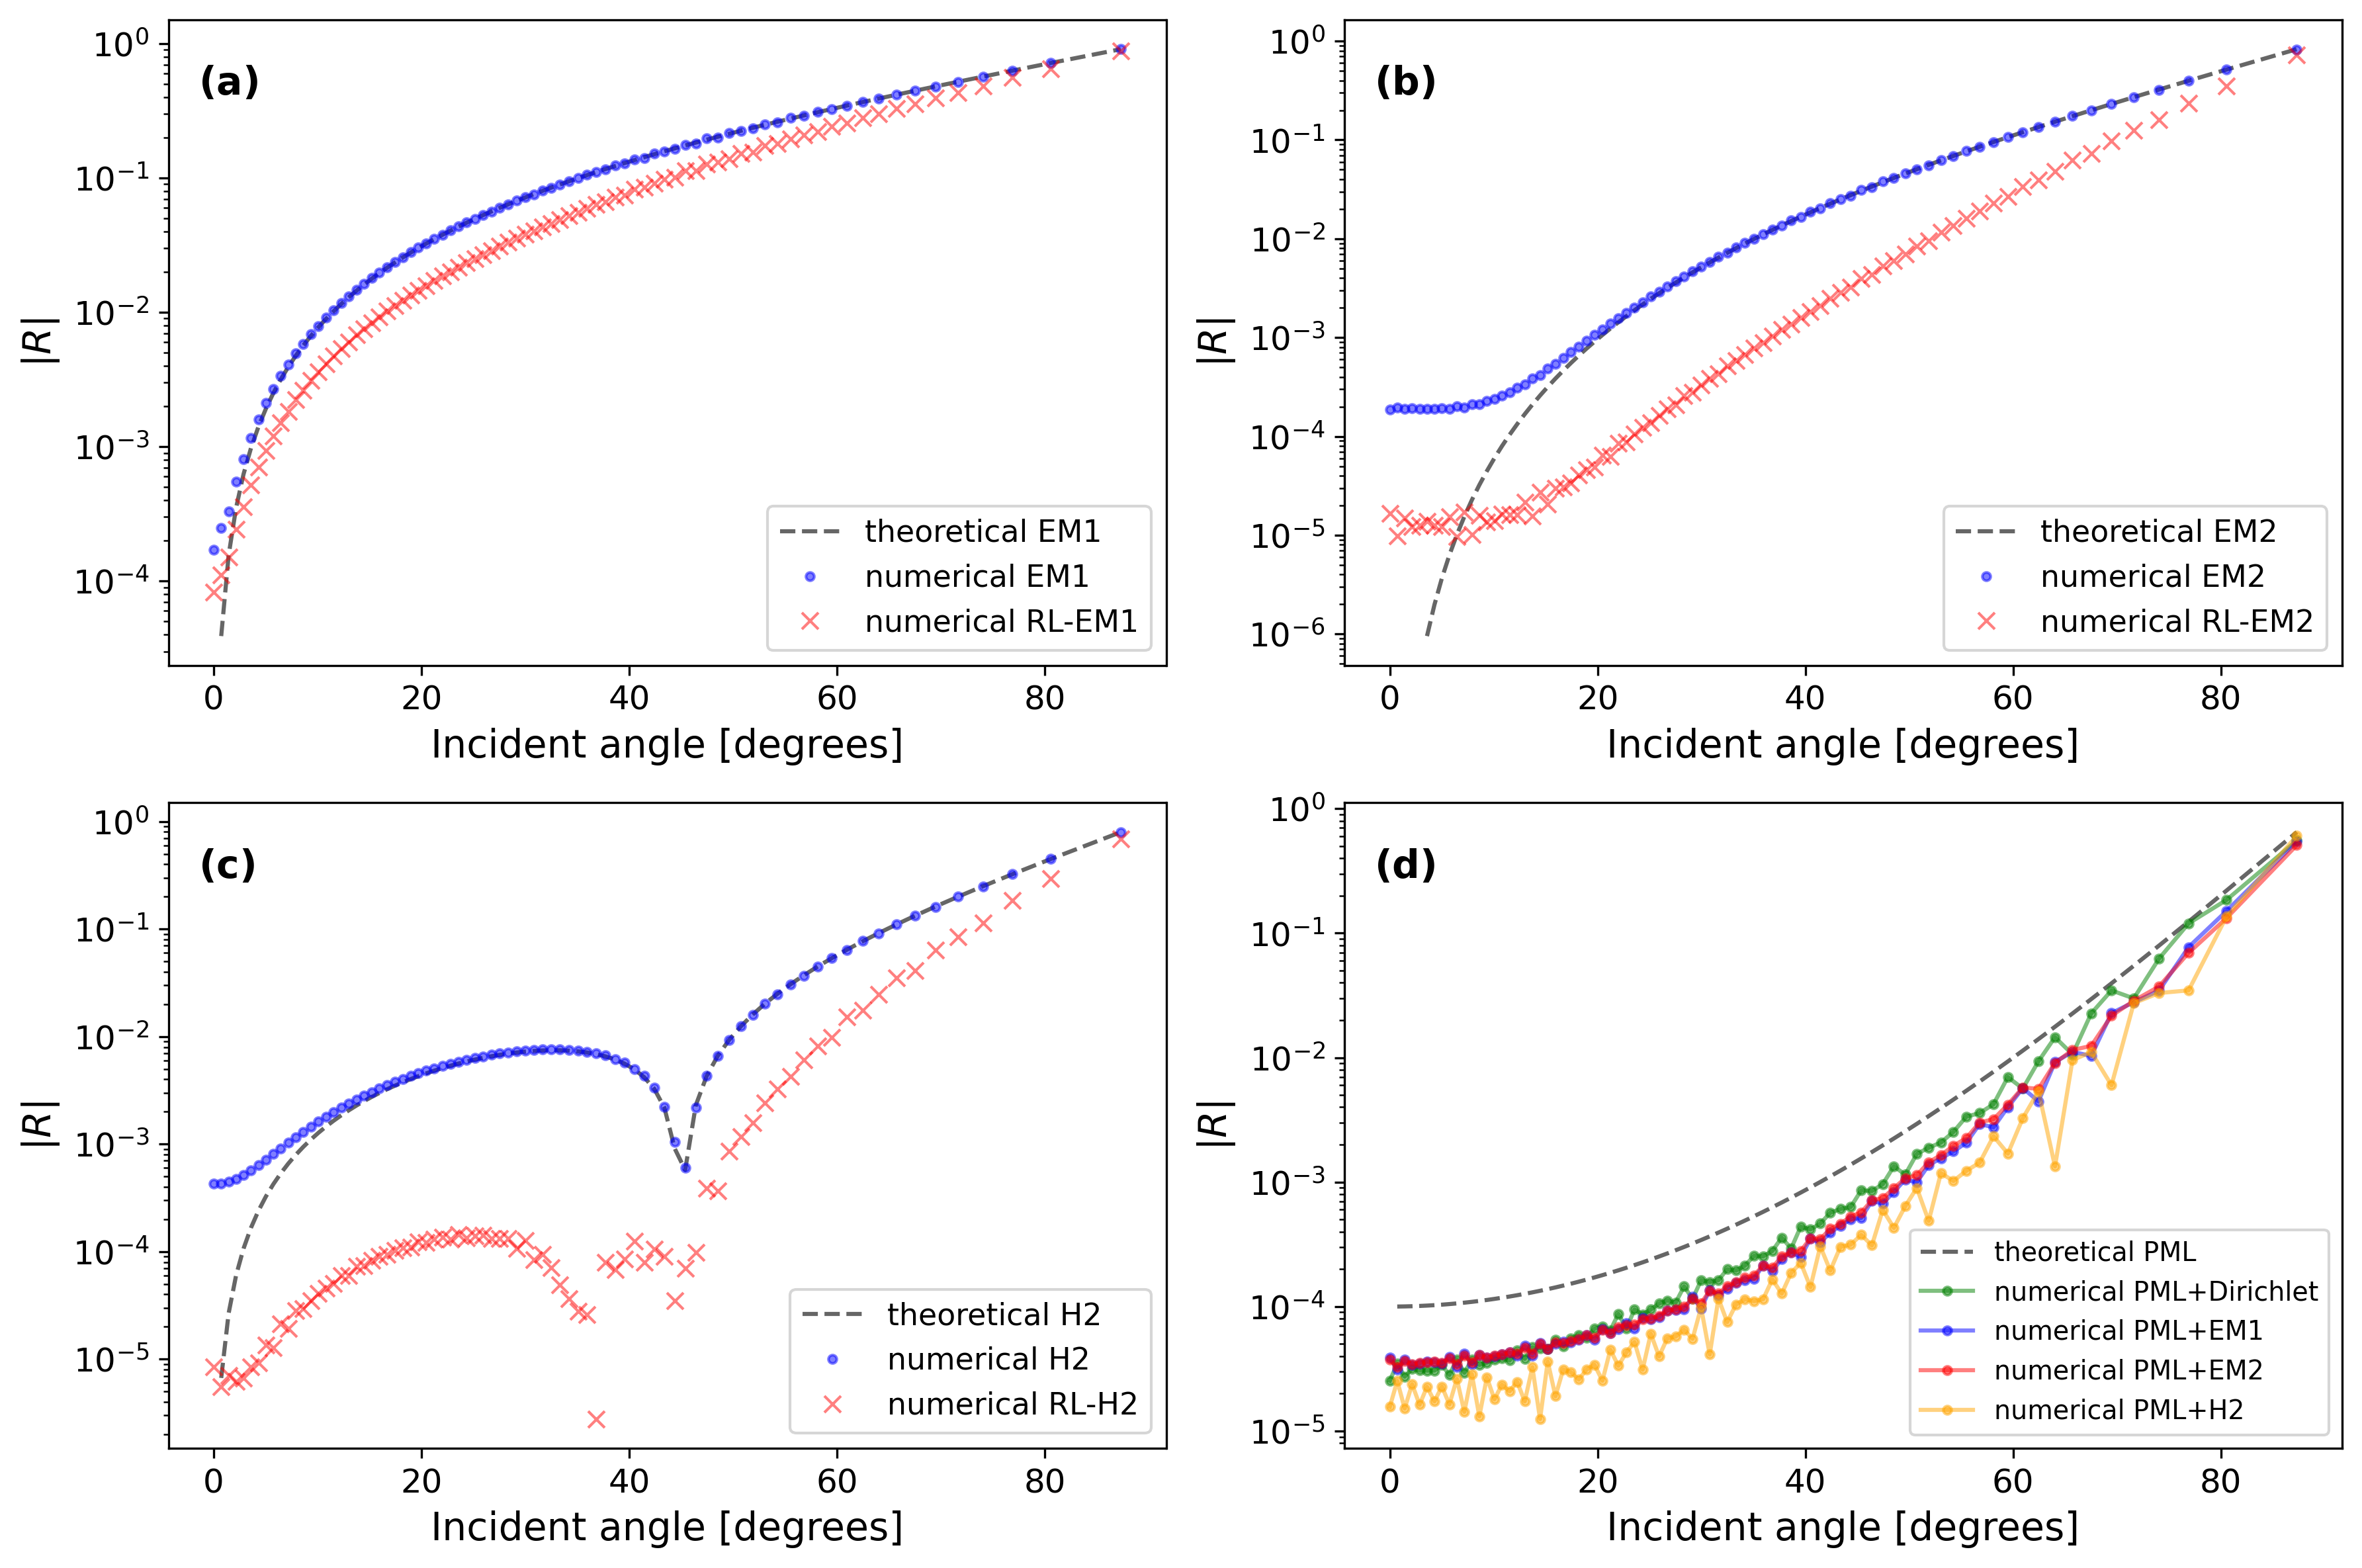

In [15]:
# Plot formatting constants
alpha = 0.5
alpha_trendline = 0.6

fontsize_xylabel = 14
fontsize_xytick = 12
fontsize_lg = 11
fontsize_tag = 14  # Fontsize for (a)-(d) labels

# Create 2x2 grid with high resolution directly in subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8), dpi=300)
axes = [ax1, ax2, ax3, ax4]

# Tags using standard LaTeX syntax:
tags = [r"$\mathbf{(a)}$", r"$\mathbf{(b)}$", r"$\mathbf{(c)}$", r"$\mathbf{(d)}$"]

k = 1
ax1.semilogy(angle[k:], np.abs(R_EM1_exact)[k:], "k--", alpha=alpha_trendline, label="theoretical EM1")
ax1.semilogy(angle, np.abs(R_EM1), ".", color="blue", alpha=alpha, label="numerical EM1")
ax1.semilogy(angle, np.abs(R_RLEM1), "x", color="red", alpha=alpha, label="numerical RL-EM1")

k = 5
ax2.semilogy(angle[k:], np.abs(R_EM2_exact)[k:], "k--", alpha=alpha_trendline, label="theoretical EM2")
ax2.semilogy(angle, np.abs(R_EM2), ".", color="blue", alpha=alpha, label="numerical EM2")
ax2.semilogy(angle, np.abs(R_RLEM2), "x", color="red", alpha=alpha, label="numerical RL-EM2")

k = 1
ax3.semilogy(angle[k:], np.abs(R_H2_exact)[k:], "k--", alpha=alpha_trendline, label="theoretical H2")
ax3.semilogy(angle, np.abs(R_H2), ".", color="blue", alpha=alpha, label="numerical H2")
ax3.semilogy(angle, np.abs(R_RLH2), "x", color="red", alpha=alpha, label="numerical RL-H2")

k = 1
ax4.semilogy(angle[k:], np.abs(R_PML0_exact)[k:], "k--",alpha=alpha_trendline, label="theoretical PML")

ax4.semilogy(angle, np.abs(R_PML0), ".-", color="green", alpha=alpha, label="numerical PML+Dirichlet") #.
ax4.semilogy(angle, np.abs(R_PMLEM1), ".-", color="blue", alpha=alpha, label="numerical PML+EM1") #x
ax4.semilogy(angle, np.abs(R_PMLEM2), ".-", color="red", alpha=alpha, label="numerical PML+EM2") #v
ax4.semilogy(angle, np.abs(R_PMLH2), ".-", color="orange", alpha=alpha, label="numerical PML+H2") #^

# --- Global formatting & Subfigure Tagging Loop ---
for ax, tag in zip(axes[:-1], tags[:-1]):
    ax.set_xlabel("Incident angle [degrees]", fontsize=fontsize_xylabel)
    ax.set_ylabel(r"$|R|$", fontsize=fontsize_xylabel)
    ax.tick_params(axis="both", labelsize=fontsize_xytick)
    ax.legend(fontsize=fontsize_lg, loc="lower right")

    # Add subfigure label (a)-(d) at top-left inside bounding box
    ax.text(0.03, 0.93, tag, transform=ax.transAxes, fontsize=fontsize_tag, fontweight="bold", verticalalignment="top", 
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=1, edgecolor="none")
    )


ax4.set_xlabel("Incident angle [degrees]", fontsize=fontsize_xylabel)
ax4.set_ylabel(r"$|R|$", fontsize=fontsize_xylabel)
ax4.tick_params(axis="both", labelsize=fontsize_xytick)
ax4.legend(fontsize=fontsize_lg-1.5, loc="lower right") # upper center

# Add subfigure label (a)-(d) at top-left inside bounding box
ax4.text(0.03, 0.93, tags[3], transform=axes[3].transAxes, fontsize=fontsize_tag, fontweight="bold", verticalalignment="top", 
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=1, edgecolor="none")
)

plt.tight_layout()
plt.show()